In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
 


In [9]:
df = pd.read_csv("C:\\Users\\phxac\\Downloads\\Project\\data\\raw\\WA_Fn-UseC_-Telco-Customer-Churn.csv")
df.shape


(7043, 21)

In [10]:
pd.set_option('display.max_columns', None) # show all columns
pd.set_option('display.max_rows', None) # show all rows


In [11]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [12]:
df1 = pd.read_csv("C:\\Users\\phxac\\Downloads\\Project\\data\\raw\\WA_Fn-UseC_-Telco-Customer-Churn.csv")
df1.head(1)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No


In [14]:
df.describe(include='all')

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043,7043.000000,7043,7043,7043.000000,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043.000000,7043,7043
unique,7043,2,NaN,2,2,NaN,2,3,3,3,3,3,3,3,3,3,2,4,NaN,6531,2
top,7590-VHVEG,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,20.2,No
freq,1,3555,NaN,3641,4933,NaN,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,NaN,11,5174
mean,NaN,NaN,0.162147,NaN,NaN,32.371149,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.761692,NaN,NaN
std,NaN,NaN,0.368612,NaN,NaN,24.559481,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090047,NaN,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,NaN,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500000,NaN,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,NaN,NaN
75%,NaN,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850000,NaN,NaN


    - Most Caterogial varibales have 2,3 or 4 Categories 
    - For Caterogires that have only 2 (binary) I will replace with 0 and 1
    - For those that have more than 2 like 3,4. I will use One-Hot Encoding

Binary Encoding

In [ ]:
binary_cols = [
    'gender', 'Partner', 'Dependents', 'PhoneService', 'PaperlessBilling', 'Churn'
]

#Mapp binary columns to 0 and 1
df[binary_cols] = df[binary_cols].replace({
    'Yes': 1, 'No': 0,
    'Male': 1, 'Female': 0
})

C:\Users\phxac\AppData\Local\Temp\ipykernel_49144\2052415682.py:5: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[binary_cols] = df[binary_cols].replace({


One_Hot Encoding

In [17]:
# Catergial Variables with more than 2 categories
categorical_cols = [
    'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
    'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaymentMethod'
]

# One-hot encode categorical variables
df = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

In [18]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,MultipleLines_No phone service,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,7590-VHVEG,0,0,1,0,1,0,1,29.85,29.85,0,True,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,True,False
1,5575-GNVDE,1,0,0,0,34,1,0,56.95,1889.5,0,False,False,False,False,False,True,False,False,False,True,False,False,False,False,False,False,True,False,False,False,True
2,3668-QPYBK,1,0,0,0,2,1,1,53.85,108.15,1,False,False,False,False,False,True,False,True,False,False,False,False,False,False,False,False,False,False,False,False,True
3,7795-CFOCW,1,0,0,0,45,0,0,42.30,1840.75,0,True,False,False,False,False,True,False,False,False,True,False,True,False,False,False,False,True,False,False,False,False
4,9237-HQITU,0,0,0,0,2,1,1,70.70,151.65,1,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False


Cleaning 

In [19]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

In [20]:
df = df.drop('customerID', axis=1)

In [21]:
bool_cols = df.select_dtypes(include='bool').columns
df[bool_cols] = df[bool_cols].astype(int) # Convert boolean columns to integers (0 and 1)

In [22]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 31 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   gender                                 7043 non-null   int64  
 1   SeniorCitizen                          7043 non-null   int64  
 2   Partner                                7043 non-null   int64  
 3   Dependents                             7043 non-null   int64  
 4   tenure                                 7043 non-null   int64  
 5   PhoneService                           7043 non-null   int64  
 6   PaperlessBilling                       7043 non-null   int64  
 7   MonthlyCharges                         7043 non-null   float64
 8   TotalCharges                           7032 non-null   float64
 9   Churn                                  7043 non-null   int64  
 10  MultipleLines_No phone service         7043 non-null   int64  
 11  Mult

In [23]:
corr_matrix = df.corr(numeric_only=True)
churn_corr = corr_matrix['Churn'].sort_values(ascending=False)
print(churn_corr)

Churn                                    1.000000
InternetService_Fiber optic              0.308020
PaymentMethod_Electronic check           0.301919
MonthlyCharges                           0.193356
PaperlessBilling                         0.191825
SeniorCitizen                            0.150889
StreamingTV_Yes                          0.063228
StreamingMovies_Yes                      0.061382
MultipleLines_Yes                        0.040102
PhoneService                             0.011942
gender                                  -0.008612
MultipleLines_No phone service          -0.011942
DeviceProtection_Yes                    -0.066160
OnlineBackup_Yes                        -0.082255
PaymentMethod_Mailed check              -0.091683
PaymentMethod_Credit card (automatic)   -0.134302
Partner                                 -0.150448
Dependents                              -0.164221
TechSupport_Yes                         -0.164674
OnlineSecurity_Yes                      -0.171226


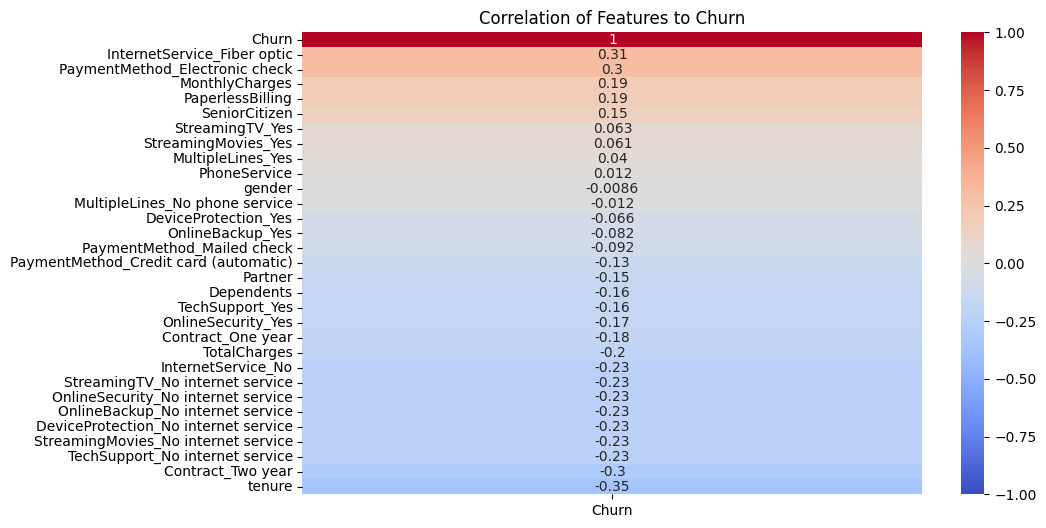

In [24]:
corr_matrix = df.corr(numeric_only=True)

churn_corr = corr_matrix['Churn'].sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.heatmap(churn_corr.to_frame(), annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation of Features to Churn')
plt.show()

Machine Learning 

In [25]:
df['Churn'].value_counts()

Churn
0    5174
1    1869
Name: count, dtype: int64

In [28]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import lightgbm as lgb 
import pandas as pd 
import time 

X = df.drop('Churn', axis=1)
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

THRESHOLD = 0.4


Random Forest Classifier

In [29]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

rf = RandomForestClassifier(n_estimators=300, random_state=42, class_weight='balanced',n_jobs=-1)

rf.fit(X_train, y_train)

proba = rf.predict_proba(X_test)[:, 1]
y_pred = (proba >= THRESHOLD).astype(int)

print("Classification Report:")
print(classification_report(y_test, y_pred, digits=3))

Classification Report:
              precision    recall  f1-score   support

           0      0.904     0.764     0.828      1036
           1      0.541     0.775     0.637       373

    accuracy                          0.767      1409
   macro avg      0.723     0.769     0.733      1409
weighted avg      0.808     0.767     0.777      1409



XGBoost Classifier 

In [30]:
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import time 

#calculate scale_pos_weight for imbalance in the dataset
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

xgb = XGBClassifier(n_estimators=300, random_state=42, scale_pos_weight=scale_pos_weight, 
                    use_label_encoder=False, eval_metric='logloss', n_jobs=-1,
                    max_depth=6, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8)

# Train Timer 
start_time = time.time()
xgb.fit(X_train, y_train)
train_time = time.time() - start_time 
print(f"Training Time: {train_time:.2f} seconds")

start_pred_time = time.time()
proba = xgb.predict_proba(X_test)[:, 1]
y_pred = (proba >= THRESHOLD).astype(int)
pred_time = time.time() - start_pred_time
print(f"Prediction Time: {pred_time:.2f} seconds")

print("Classification Report:")
print(classification_report(y_test, y_pred, digits=3))


c:\Users\phxac\Downloads\Project\.venv\Lib\site-packages\xgboost\training.py:200: UserWarning: [15:16:34] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Training Time: 0.88 seconds
Prediction Time: 0.02 seconds
Classification Report:
              precision    recall  f1-score   support

           0      0.920     0.725     0.811      1036
           1      0.519     0.826     0.638       373

    accuracy                          0.752      1409
   macro avg      0.720     0.775     0.724      1409
weighted avg      0.814     0.752     0.765      1409



Hyperparameter tuning & Experiment tracking (MLFlow)

In [32]:
import optuna
from xgboost import XGBClassifier
from sklearn.metrics import recall_score
from sklearn.model_selection import train_test_split

# Objective function for Optuna
def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 300, 800),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3),
        "max_depth": trial.suggest_int("max_depth", 3, 10),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
        "reg_alpha": trial.suggest_float("reg_alpha", 0, 5),
        "reg_lambda": trial.suggest_float("reg_lambda", 0, 5),
        "scale_pos_weight": (y_train == 0).sum() / (y_train == 1).sum(),
        "eval_metric": "logloss",
        "gamma": trial.suggest_float("gamma", 0, 5),
        "random_state": 42,
        "n_jobs": -1
    }

    model = XGBClassifier(**params)

    model.fit(X_train, y_train)
    proba = model.predict_proba(X_test)[:, 1]
    y_pred = (proba >= THRESHOLD).astype(int)
    return recall_score(y_test, y_pred)

# Run Optuna optimization
study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=50)

print("Best Hyperparameters:", study.best_params)
print("Best Recall Score:", study.best_value)

c:\Users\phxac\Downloads\Project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[I 2026-06-12 15:29:36,564] A new study created in memory with name: no-name-32988550-f635-4ffe-83bb-365cc191ede6
[I 2026-06-12 15:29:37,351] Trial 0 finished with value: 0.8337801608579088 and parameters: {'n_estimators': 623, 'learning_rate': 0.26447670640457527, 'max_depth': 9, 'subsample': 0.5074544999507425, 'colsample_bytree': 0.6789428143645837, 'min_child_weight': 8, 'reg_alpha': 1.9934406583929958, 'reg_lambda': 2.376969171255899, 'gamma': 4.0581117109490314}. Best is trial 0 with value: 0.8337801608579088.
[I 2026-06-12 15:29:38,651] Trial 1 finished with value: 0.6997319034852547 and parameters: {'n_estimators': 620, 'learning_rate': 0.17592299179653484, 'max_depth': 6, 'subsample': 0.5731453119558951, 'colsample_bytr

Best Hyperparameters: {'n_estimators': 713, 'learning_rate': 0.010625867162450724, 'max_depth': 3, 'subsample': 0.9623003434337472, 'colsample_bytree': 0.9810822846996683, 'min_child_weight': 4, 'reg_alpha': 3.4238277071169496, 'reg_lambda': 4.785300048154086, 'gamma': 3.889675207937219}
Best Recall Score: 0.900804289544236


In [35]:
from xgboost import XGBClassifier
from sklearn.metrics import classification_report
import time

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

# Use best hyperparameters from Optuna
best_params = study.best_params
best_params.update({
    "eval_metric": "logloss",
    "random_state": 42,
    "n_jobs": -1,
    "scale_pos_weight": scale_pos_weight
})


xgb_optimized = XGBClassifier(**best_params)

start_time = time.time()
xgb_optimized.fit(X_train, y_train)
train_time = time.time() - start_time
print(f"Optimized Training Time: {train_time:.2f} seconds")

print("Classification Report for Optimized XGBoost:")
print(classification_report(y_test, y_pred, digits=3))

Optimized Training Time: 1.03 seconds
Classification Report for Optimized XGBoost:
              precision    recall  f1-score   support

           0      0.920     0.725     0.811      1036
           1      0.519     0.826     0.638       373

    accuracy                          0.752      1409
   macro avg      0.720     0.775     0.724      1409
weighted avg      0.814     0.752     0.765      1409




This tuned XBoost is doing exactly what Optuna optimized for - maximizing recall for churners:
• Recall (class 1): 0.826 (highest we've seen so far)
• Precision (class 1): 0.519 (low - many loyal customers are being flagged)
• F1 (class 1): 0.638

Interpretation
• This model is catching almost all churners, which is great if you're running aggressive retention campaigns and the cost of contacting non-churners is low.
• But the low precision means more than half of the people you target won't actually churn.
